In [12]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid
import mpl_scatter_density
from matplotlib.colors import LinearSegmentedColormap
import pyBigWig

**Finding top peak signal for cycle 1 removed calls**

In [3]:
#load npz file
added_delta_all_cycles = []
removed_delta_all_cycles = []
added_flat_inds_all_cycles = []
removed_flat_inds_all_cycles = []

for i in range(1, 11):
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffbiosample_sorteddiffdhs_fillsize100unique_cycle'+str(i)+'_added_removed_CT20220302.npz'
    cycle_np_file = np.load(filename)
    added_delta_all_cycles.append(cycle_np_file['added_delta'])
    removed_delta_all_cycles.append(cycle_np_file['removed_delta'])
    added_flat_inds_all_cycles.append(cycle_np_file['added_flat_inds'])
    removed_flat_inds_all_cycles.append(cycle_np_file['removed_flat_inds'])

In [4]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [5]:
file = '/home/ctrader/NMF_data/DHS_signal_matrix/DHS_peak_signal_hg38.75_20.normalized.GRCh38_no_alts_array_CT20220215.npy'
DHS_peak_signal_array = np.load(file)

In [6]:
n_biosamples, n_DHSs = DHS_peak_signal_array.shape

In [7]:
#loading biosample metadata
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
biosample_df = pd.read_csv(tsv_file, delimiter="\t")

In [8]:
#finding peak signal values of added calls
removed_peak_signal_all_cycles = []
for i in range(10):
    print(i)
    removed_peak_signal_single_cycle = []
    for biosample, dhs in zip((removed_flat_inds_all_cycles[i] // n_DHSs), (removed_flat_inds_all_cycles[i] % n_DHSs)):
        removed_peak_signal_single_cycle.append(DHS_peak_signal_array[biosample, dhs])
    removed_peak_signal_single_cycle = np.array(removed_peak_signal_single_cycle)
    removed_peak_signal_all_cycles.append(removed_peak_signal_single_cycle)

0
1
2
3
4
5
6
7
8
9


In [9]:
#looking into the top peak signal -1 removed calls
top_100_peak_scores = np.flip(np.sort(removed_peak_signal_all_cycles[0])[-100:])

top_100_neg1_peak_signal_flat_inds = removed_flat_inds_all_cycles[0][np.argsort(-removed_peak_signal_all_cycles[0])[:100]]
top_100_neg1_peak_signal_DHS_inds = top_100_neg1_peak_signal_flat_inds % n_DHSs
top_100_neg1_peak_signal_biosample_inds = top_100_neg1_peak_signal_flat_inds // n_DHSs
top_100_neg1_peak_signal_biosamples = np.array(biosample_df.loc[top_100_neg1_peak_signal_biosample_inds]['Biosample name'])

top_100_neg1_peak_signal_chr = np.array(DHS_metadata.loc[top_100_neg1_peak_signal_DHS_inds]['seqname'])
top_100_neg1_peak_signal_start = np.array(DHS_metadata.loc[top_100_neg1_peak_signal_DHS_inds]['start'])
top_100_neg1_peak_signal_end = np.array(DHS_metadata.loc[top_100_neg1_peak_signal_DHS_inds]['end'])

In [16]:
today = date.today()
bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_delta_100unique_top_100_peak_signal_removed_calls_cycle1_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(100):
    f.write(str(top_100_neg1_peak_signal_chr[i]) + '\t' + str(top_100_neg1_peak_signal_start[i]) + '\t' + str(top_100_neg1_peak_signal_end[i]) + '\t' + str(top_100_peak_scores[i]) + ' ' + str(top_100_neg1_peak_signal_biosamples[i]) + '\n')
f.close()
link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_delta_100unique_top_100_peak_signal_removed_calls_cycle1_CT' + today.strftime("%Y%m%d") + '.bed'
print(link_path)

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_delta_100unique_top_100_peak_signal_removed_calls_cycle1_CT20220304.bed


**Seeing if there are cases of a DHS being reassigned to a nearby DHS**

In [45]:
cycle0_dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')

In [217]:
i = 12
biosample = top_100_neg1_peak_signal_biosample_inds[i]
dhs = top_100_neg1_peak_signal_DHS_inds[i]
chrm = top_100_neg1_peak_signal_chr[i]
start = top_100_neg1_peak_signal_start[i]-100
end = top_100_neg1_peak_signal_end[i]+100

In [218]:
agnum = biosample_df.loc[biosample]['Altius Aggregation ID'][2:]
lnnum = biosample_df.loc[biosample]['Altius Library ID']
read_in_question_biosample_name = biosample_df.loc[biosample]['Biosample name']
print(agnum)
print(lnnum)
filename = '/net/seq/data/aggregations/' + lnnum + '/aggregation-' + agnum + '/' + lnnum + '.75_20.normalized.GRCh38_no_alts.bw'
bw_file = pyBigWig.open(filename)
read_in_question = bw_file.values(chrm, 
                                  start, 
                                  end, 
                                  numpy=True)

4040
LN4858


In [219]:
np.where(cycle0_dhs_arr[:, dhs]==True)

(array([ 42,  78,  86,  87, 101, 129, 130, 136, 143, 144, 152, 168, 169,
        175, 181, 182, 183, 189, 191, 205, 208, 209, 210, 211, 212, 213,
        222, 227, 228, 234, 235, 242, 243, 244, 249, 258, 259, 261, 264,
        266, 275, 276, 277, 281, 282, 285, 286, 289, 290, 292, 293, 296,
        297, 298, 299, 306, 307, 308, 309, 312, 315, 316, 317, 319, 321,
        323, 324, 325, 326, 329, 330, 333, 336, 337, 345, 346, 347, 348,
        349, 350, 358, 359, 361, 362, 363, 364, 365, 366, 368, 369, 370,
        371, 372, 374, 376, 377, 381, 385, 386, 392, 393, 394, 395, 396,
        398, 399, 405, 406, 409, 410, 411, 412, 413, 414, 416, 417, 419,
        420, 421, 422, 426, 427, 432, 433, 434, 445, 446, 447, 448, 455,
        456, 457, 458, 464, 465, 471, 472, 474, 475, 476, 477, 478, 482,
        483, 486, 503, 504, 505, 512, 513, 514, 515, 516, 517, 518, 519,
        520, 521, 522, 523, 529, 530, 531, 540, 541, 561, 566, 571, 576,
        586, 587, 588, 589, 591, 599, 600, 601, 602

In [220]:
biosample_df[biosample_df['Biosample name'] == 'fLung_L']

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index
213,214,fLung_L,NaN,ENCSR541AVF,ENCLB488FIS,ENCBS287DAY,AG9115,LN3399,DS15637,NaN,...,minElute,80.0,60.2,15400000.0,A+Sucrose,2010-07-07,35392237,0.4294,59972,59687
235,236,fLung_L,NaN,ENCSR960EJV,ENCLB419ZLR,ENCBS647OUP,AG9094,LN3716,DS16570,NaN,...,minElute,80.0,73,7040000.0,A+Sucrose,2010-09-09,37843202,0.5059,64580,64294
259,260,fLung_L,NaN,ENCSR803VCR,ENCLB075MKH,ENCBS114AZP,AG9074,LN3874,DS17105,NaN,...,minElute,80.0,64,5100000.0,A+Sucrose,2010-10-26,33307832,0.5563,63808,63489
264,265,fLung_L,NaN,ENCSR680SDS,ENCLB727PHD,ENCBS188SKM,AG9069,LN3895,DS17154,NaN,...,minElute,80.0,18.2,5280000.0,A+Sucrose,2010-11-01,52173786,0.5449,76447,76011
292,293,fLung_L,NaN,ENCSR488PHT,ENCLB348PVS,ENCBS960KKK,AG9036,LN3973,DS17464,NaN,...,minElute,60.0,24.2,6170000.0,A+Sucrose,2010-12-06,38587147,0.5163,63779,63516
309,310,fLung_L,Pulmonary devel.,ENCSR456KDF,ENCLB731WYV,ENCBS078XUR,AG9020,LN4057,DS17674,NaN,...,minElute,60.0,9.4,5460000.0,A+Sucrose,2011-01-06,21264511,0.6124,66020,65884
312,313,fLung_L,NaN,ENCSR510ITB,ENCLB020YSU,ENCBS574MIZ,AG9016,LN4063,DS17739,NaN,...,minElute,60.0,13.9,8590000.0,A+Sucrose,2011-01-12,19700183,0.5429,54786,54692
326,327,fLung_L,NaN,ENCSR006XED,ENCLB309SGY,ENCBS859ASH,AG9000,LN4086,DS17835,NaN,...,minElute,60.0,3.3,7650000.0,A+Sucrose,2011-01-25,11589339,0.5242,30080,30019
337,338,fLung_L,NaN,ENCSR468OVW,ENCLB622ECR,ENCBS143LJK,AG8989,LN4108,DS17959,NaN,...,minElute,60.0,77.4,8030000.0,A+Sucrose,2011-02-07,33762344,0.5170,53944,53658
348,349,fLung_L,Pulmonary devel.,ENCSR935EVZ,ENCLB495CPV,ENCBS587TEK,AG8983,LN4148,DS18170,NaN,...,minElute,80.0,43.2,12750000.0,A+Sucrose,2011-02-22,88248559,0.6780,142545,142220


In [221]:
# base_biosample = 660 #1
# base_biosample = 727 #2
# base_biosample = 262 #3
# base_biosample = 618 #4
base_biosample = 213 #13

In [223]:
agnum = biosample_df.loc[base_biosample]['Altius Aggregation ID'][2:]
lnnum = biosample_df.loc[base_biosample]['Altius Library ID']
base_read_biosample_name = biosample_df.loc[base_biosample]['Biosample name']
print(agnum)
print(lnnum)
filename = '/net/seq/data/aggregations/' + lnnum + '/aggregation-' + agnum + '/' + lnnum + '.75_20.normalized.GRCh38_no_alts.bw'
bw_file = pyBigWig.open(filename)
base_read = bw_file.values(chrm, 
                           start, 
                           end, 
                           numpy=True)

9115
LN3399


In [224]:
dhs_name = DHS_metadata.loc[dhs]['identifier']

Text(0.5, 1.0, 'BigWig Signal Values at DHS 3.25471 for Removed Call in Biosample Skin_Keratinocytes with Delta=104.294\nDelta Flip, Flip Size=100 Unique Delta Values')

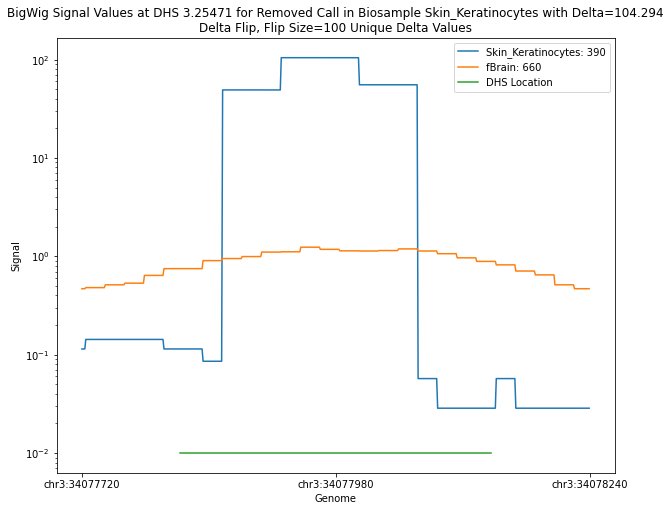

In [141]:
fig = plt.figure(figsize=(10,8))
fig.patch.set_facecolor('white')

plt.plot(np.arange(len(read_in_question)), read_in_question)
plt.plot(np.arange(len(base_read)), base_read)
dhs_len = top_100_neg1_peak_signal_end[i] - top_100_neg1_peak_signal_start[i]
plt.plot(np.arange(100, 100+dhs_len), np.zeros(dhs_len)+0.01)

plt.xticks([0, len(read_in_question)/2, len(read_in_question)], 
           [top_100_neg1_peak_signal_chr[i] + ':' + str(top_100_neg1_peak_signal_start[i]-100), top_100_neg1_peak_signal_chr[i] + ':' + str(int((top_100_neg1_peak_signal_end[i]+100 + top_100_neg1_peak_signal_start[i]-100)/2)), top_100_neg1_peak_signal_chr[i] + ':' + str(top_100_neg1_peak_signal_end[i]+100)])

plt.legend([read_in_question_biosample_name + ': ' + str(biosample), 
            base_read_biosample_name + ': ' + str(base_biosample),
            'DHS Location'])
plt.yscale('log')
# plt.xlim([0, 175])
# # plt.xlim([22453, 22553])
plt.xlabel('Genome')
plt.ylabel('Signal')
plt.title('BigWig Signal Values at DHS %s for Removed Call in Biosample %s with Delta=%s\nDelta Flip, Flip Size=100 Unique Delta Values' %(dhs_name, read_in_question_biosample_name, top_100_peak_scores[i]))

Text(0.5, 1.0, 'BigWig Signal Values at DHS 5.8642621 for Removed Call in Biosample Skin_Keratinocytes with Delta=76.7927\nDelta Flip, Flip Size=100 Unique Delta Values')

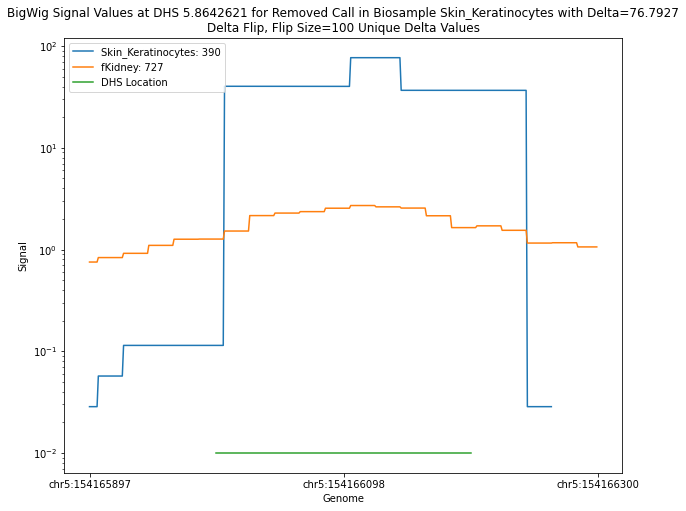

In [159]:
fig = plt.figure(figsize=(10,8))
fig.patch.set_facecolor('white')

plt.plot(np.arange(len(read_in_question)), read_in_question)
plt.plot(np.arange(len(base_read)), base_read)
dhs_len = top_100_neg1_peak_signal_end[i] - top_100_neg1_peak_signal_start[i]
plt.plot(np.arange(100, 100+dhs_len), np.zeros(dhs_len)+0.01)

plt.xticks([0, len(read_in_question)/2, len(read_in_question)], 
           [top_100_neg1_peak_signal_chr[i] + ':' + str(top_100_neg1_peak_signal_start[i]-100), top_100_neg1_peak_signal_chr[i] + ':' + str(int((top_100_neg1_peak_signal_end[i]+100 + top_100_neg1_peak_signal_start[i]-100)/2)), top_100_neg1_peak_signal_chr[i] + ':' + str(top_100_neg1_peak_signal_end[i]+100)])

plt.legend([read_in_question_biosample_name + ': ' + str(biosample), 
            base_read_biosample_name + ': ' + str(base_biosample),
            'DHS Location'], loc = 'upper left')
plt.yscale('log')
# plt.xlim([0, 175])
# # plt.xlim([22453, 22553])
plt.xlabel('Genome')
plt.ylabel('Signal')
plt.title('BigWig Signal Values at DHS %s for Removed Call in Biosample %s with Delta=%s\nDelta Flip, Flip Size=100 Unique Delta Values' %(dhs_name, read_in_question_biosample_name, top_100_peak_scores[i]))

Text(0.5, 1.0, 'BigWig Signal Values at DHS 6.2045652 for Removed Call in Biosample Skin_Keratinocytes with Delta=29.3577\nDelta Flip, Flip Size=100 Unique Delta Values')

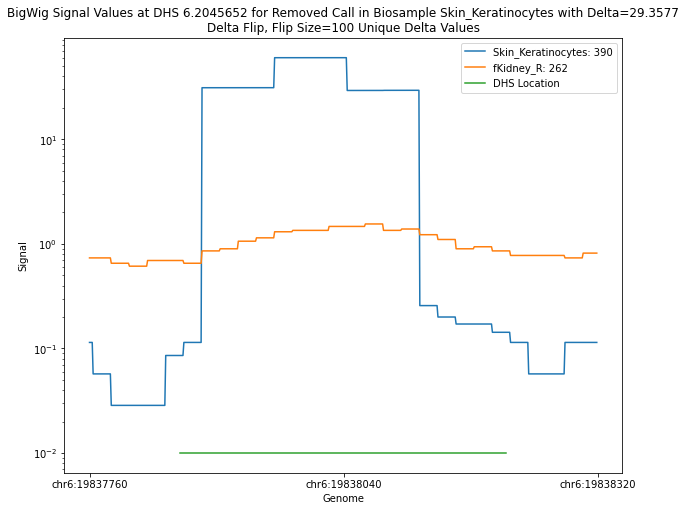

In [168]:
fig = plt.figure(figsize=(10,8))
fig.patch.set_facecolor('white')

plt.plot(np.arange(len(read_in_question)), read_in_question)
plt.plot(np.arange(len(base_read)), base_read)
dhs_len = top_100_neg1_peak_signal_end[i] - top_100_neg1_peak_signal_start[i]
plt.plot(np.arange(100, 100+dhs_len), np.zeros(dhs_len)+0.01)

plt.xticks([0, len(read_in_question)/2, len(read_in_question)], 
           [top_100_neg1_peak_signal_chr[i] + ':' + str(top_100_neg1_peak_signal_start[i]-100), top_100_neg1_peak_signal_chr[i] + ':' + str(int((top_100_neg1_peak_signal_end[i]+100 + top_100_neg1_peak_signal_start[i]-100)/2)), top_100_neg1_peak_signal_chr[i] + ':' + str(top_100_neg1_peak_signal_end[i]+100)])

plt.legend([read_in_question_biosample_name + ': ' + str(biosample), 
            base_read_biosample_name + ': ' + str(base_biosample),
            'DHS Location'])
plt.yscale('log')
# plt.xlim([0, 175])
# # plt.xlim([22453, 22553])
plt.xlabel('Genome')
plt.ylabel('Signal')
plt.title('BigWig Signal Values at DHS %s for Removed Call in Biosample %s with Delta=%s\nDelta Flip, Flip Size=100 Unique Delta Values' %(dhs_name, read_in_question_biosample_name, top_100_peak_scores[i]))

Text(0.5, 1.0, 'BigWig Signal Values at DHS 2.962169 for Removed Call in Biosample Skin_Keratinocytes with Delta=12.0515\nDelta Flip, Flip Size=100 Unique Delta Values')

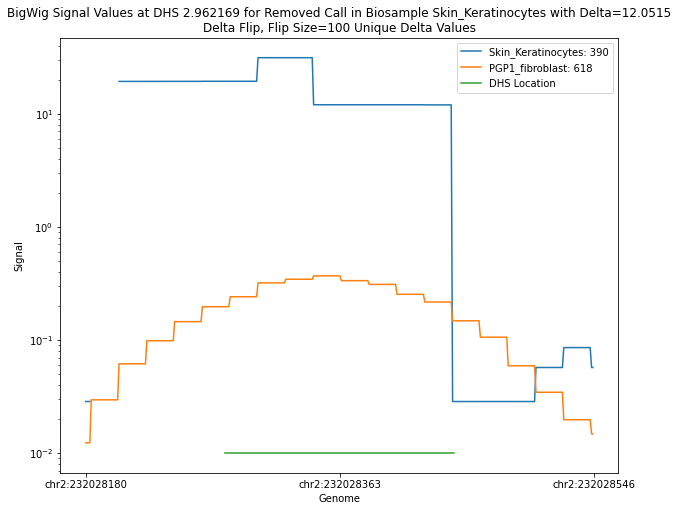

In [216]:
fig = plt.figure(figsize=(10,8))
fig.patch.set_facecolor('white')

plt.plot(np.arange(len(read_in_question)), read_in_question)
plt.plot(np.arange(len(base_read)), base_read)
dhs_len = top_100_neg1_peak_signal_end[i] - top_100_neg1_peak_signal_start[i]
plt.plot(np.arange(100, 100+dhs_len), np.zeros(dhs_len)+0.01)

plt.xticks([0, len(read_in_question)/2, len(read_in_question)], 
           [top_100_neg1_peak_signal_chr[i] + ':' + str(top_100_neg1_peak_signal_start[i]-100), top_100_neg1_peak_signal_chr[i] + ':' + str(int((top_100_neg1_peak_signal_end[i]+100 + top_100_neg1_peak_signal_start[i]-100)/2)), top_100_neg1_peak_signal_chr[i] + ':' + str(top_100_neg1_peak_signal_end[i]+100)])

plt.legend([read_in_question_biosample_name + ': ' + str(biosample), 
            base_read_biosample_name + ': ' + str(base_biosample),
            'DHS Location'])
plt.yscale('log')
# plt.xlim([0, 175])
# # plt.xlim([22453, 22553])
plt.xlabel('Genome')
plt.ylabel('Signal')
plt.title('BigWig Signal Values at DHS %s for Removed Call in Biosample %s with Delta=%s\nDelta Flip, Flip Size=100 Unique Delta Values' %(dhs_name, read_in_question_biosample_name, top_100_peak_scores[i]))

Text(0.5, 1.0, 'BigWig Signal Values at DHS 2.866872 for Removed Call in Biosample LHCN_M2 with Delta=8.28356\nDelta Flip, Flip Size=100 Unique Delta Values')

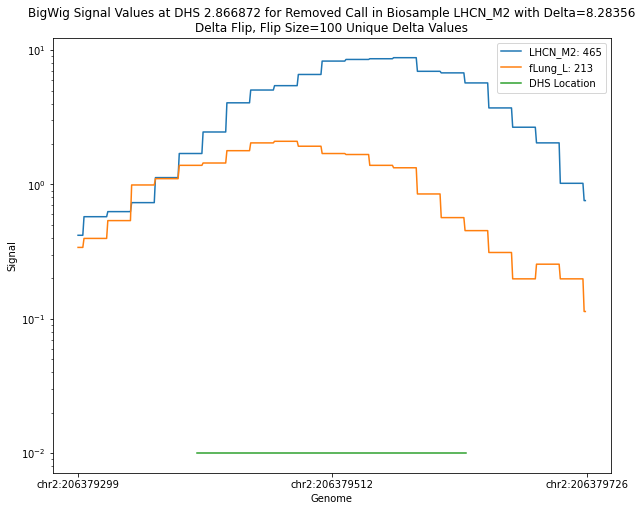

In [225]:
fig = plt.figure(figsize=(10,8))
fig.patch.set_facecolor('white')

plt.plot(np.arange(len(read_in_question)), read_in_question)
plt.plot(np.arange(len(base_read)), base_read)
dhs_len = top_100_neg1_peak_signal_end[i] - top_100_neg1_peak_signal_start[i]
plt.plot(np.arange(100, 100+dhs_len), np.zeros(dhs_len)+0.01)

plt.xticks([0, len(read_in_question)/2, len(read_in_question)], 
           [top_100_neg1_peak_signal_chr[i] + ':' + str(top_100_neg1_peak_signal_start[i]-100), top_100_neg1_peak_signal_chr[i] + ':' + str(int((top_100_neg1_peak_signal_end[i]+100 + top_100_neg1_peak_signal_start[i]-100)/2)), top_100_neg1_peak_signal_chr[i] + ':' + str(top_100_neg1_peak_signal_end[i]+100)])

plt.legend([read_in_question_biosample_name + ': ' + str(biosample), 
            base_read_biosample_name + ': ' + str(base_biosample),
            'DHS Location'])
plt.yscale('log')
# plt.xlim([0, 175])
# # plt.xlim([22453, 22553])
plt.xlabel('Genome')
plt.ylabel('Signal')
plt.title('BigWig Signal Values at DHS %s for Removed Call in Biosample %s with Delta=%s\nDelta Flip, Flip Size=100 Unique Delta Values' %(dhs_name, read_in_question_biosample_name, top_100_peak_scores[i]))